# Óxidos anfóteros, neutros e mistos
### Funções inorgânicas — óxidos

**Objetivo:** Explicar o anfoterismo do $\mathrm{Al_2O_3}$ e do $\mathrm{ZnO}$, o comportamento inerte do CO e os óxidos mistos como $\mathrm{Fe_3O_4}$.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

Três grupos de óxidos que fogem da regra "metal = básico, ametal = ácido":

**Anfóteros** — reagem com ácido **e** com base. Os casos que aparecem no ensino médio são o óxido de alumínio e o de zinco:

$$
\boxed{
\begin{aligned}
\mathrm{Al_2O_3 + 6HCl} &\rightarrow \mathrm{2AlCl_3 + 3H_2O}\\
\mathrm{Al_2O_3 + 2NaOH} &\rightarrow \mathrm{2NaAlO_2 + H_2O}
\end{aligned}}
$$

O segundo produto, o aluminato de sódio, mostra o óxido agindo como **ácido** (doando $\mathrm{Al_2O_3}$ para uma base). É por isso que o alumínio "desaparece" em contato com soda cáustica — e por que não se guarda soda em panela de alumínio.

**Neutros** — não reagem com água, ácido nem base diluídos: $\mathrm{CO}$, $\mathrm{NO}$, $\mathrm{N_2O}$.

**Óxidos duplos/mistos** — resultado da combinação de dois óxidos do mesmo metal, como a magnetita $\mathrm{Fe_3O_4}$, que é $\mathrm{FeO \cdot Fe_2O_3}$.

## 2. Exemplo resolvido passo a passo

**Limpeza de panela de alumínio com soda.** Uma panela perde $0{,}54\ \mathrm{g}$ de $\mathrm{Al_2O_3}$ (a camada de óxido protetora) em contato com soda. Quantos mols de $\mathrm{NaOH}$ foram consumidos?

**Passo 1 — massa molar do $\mathrm{Al_2O_3}$.**

$$
M = 2 \cdot 26{,}98 + 3 \cdot 16{,}00 = 101{,}96\ \mathrm{g/mol}
$$

**Passo 2 — mols de óxido.**

$$
n = \frac{0{,}54}{101{,}96} = 5{,}30\times10^{-3}\ \mathrm{mol}
$$

**Passo 3 — proporção (2 NaOH por 1 Al₂O₃).**

$$
n_{\mathrm{NaOH}} = 2 \cdot 5{,}30\times10^{-3} = \boxed{1{,}06\times10^{-2}\ \mathrm{mol}}
$$

**Passo 4 — volume de soda 0,50 mol/L.**

$$
V = \frac{n}{c} = \frac{1{,}06\times10^{-2}}{0{,}50} = 0{,}021\ \mathrm{L} \approx 21\ \mathrm{mL}
$$

Pouco volume, mas suficiente para corroer a camada protetora e liberar hidrogênio (é a "fervura" que se vê):

$$
\mathrm{2Al + 2NaOH + 2H_2O \rightarrow 2NaAlO_2 + 3H_2\uparrow}
$$

## 3. Conferindo o cálculo com Python

In [2]:
# @title Al2O3 + NaOH
from rdkit import Chem
from rdkit.Chem import Descriptors

M_AL2O3 = Descriptors.MolWt(Chem.MolFromSmiles("[Al+3].[Al+3].[O-2].[O-2].[O-2]"))
massa = 0.54          # g de Al2O3 dissolvidos
c_naoh = 0.50         # mol/L

n_al2o3 = massa / M_AL2O3
n_naoh = 2 * n_al2o3
volume = n_naoh / c_naoh

print(f"M(Al2O3)  = {M_AL2O3:.2f} g/mol")
print(f"n(Al2O3)  = {n_al2o3:.2e} mol")
print(f"n(NaOH)   = {n_naoh:.2e} mol")
print(f"V de soda 0,50 mol/L = {volume * 1000:.1f} mL")
print(f"hidrogênio liberado (2Al + 2NaOH) = {n_naoh * 1.5:.2e} mol de H2")

M(Al2O3)  = 101.96 g/mol
n(Al2O3)  = 5.30e-03 mol
n(NaOH)   = 1.06e-02 mol
V de soda 0,50 mol/L = 21.2 mL
hidrogênio liberado (2Al + 2NaOH) = 1.59e-02 mol de H2


## 4. Visualização

### 4.1 Óxido de alumínio em 3D — arraste para girar

O $\mathrm{Al_2O_3}$ (alumina) é o óxido anfótero clássico. Dois $\mathrm{Al^{3+}}$ e três $\mathrm{O^{2-}}$ na menor unidade de fórmula — é também o material do rubi e da safira (com traços de impurezas).

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("[Al+3].[Al+3].[O-2].[O-2].[O-2]", altura=460)

[16:36:12] UFFTYPER: Warning: hybridization set to SP3 for atom 0
[16:36:12] UFFTYPER: Unrecognized charge state for atom: 0
[16:36:12] UFFTYPER: Warning: hybridization set to SP3 for atom 0
[16:36:12] UFFTYPER: Unrecognized charge state for atom: 0
[16:36:12] UFFTYPER: Warning: hybridization set to SP3 for atom 0
[16:36:12] UFFTYPER: Unrecognized charge state for atom: 0
[16:36:12] UFFTYPER: Warning: hybridization set to SP3 for atom 1
[16:36:12] UFFTYPER: Unrecognized charge state for atom: 1


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 Óxido de zinco em 3D

O $\mathrm{ZnO}$ também é anfótero e é o pó branco do protetor solar físico (bloqueia UV). Gire e veja o par $\mathrm{Zn^{2+}}$/$\mathrm{O^{2-}}$.

In [4]:
molecula_3d("[Zn+2].[O-2]")

[16:36:12] UFFTYPER: Unrecognized charge state for atom: 0
[16:36:12] UFFTYPER: Unrecognized atom type: Zn+2 (0)
[16:36:12] UFFTYPER: Unrecognized charge state for atom: 0
[16:36:12] UFFTYPER: Unrecognized atom type: Zn+2 (0)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 Monóxido de carbono em 3D: o óxido neutro

O $\mathrm{CO}$ tem uma **ligação tripla** (ou dupla mais um par de elétrons cedido, no modelo de Lewis): $\mathrm{C\equiv O}$ com cargas formais. É inodoro, insípido e tóxico — liga-se à hemoglobina com afinidade $\approx200$ vezes maior que o $\mathrm{O_2}$.

In [5]:
molecula_3d("[C-]#[O+]")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.4 Os três em 2D, com os risquinhos

O $\mathrm{CO}$ aparece com **três riscos** entre C e O — é a ligação tripla. Compare com o $\mathrm{CO_2}$, que tem duas duplas.

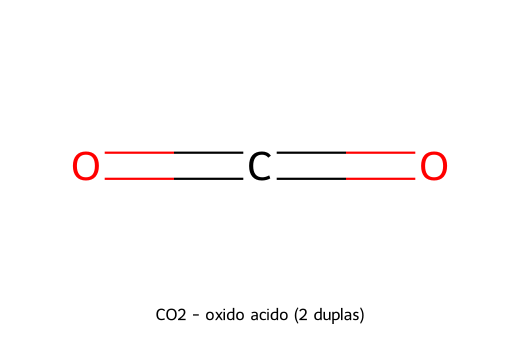

In [6]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("[Al+3].[Al+3].[O-2].[O-2].[O-2]", legenda="Al2O3 - oxido anfotero")
estrutura_2d("[Zn+2].[O-2]", legenda="ZnO - oxido anfotero")
estrutura_2d("[C-]#[O+]", legenda="CO - oxido neutro (ligacao tripla)")
estrutura_2d("O=C=O", legenda="CO2 - oxido acido (2 duplas)")

### 4.5 Anfoterismo na prática: alumínio em meio ácido e básico

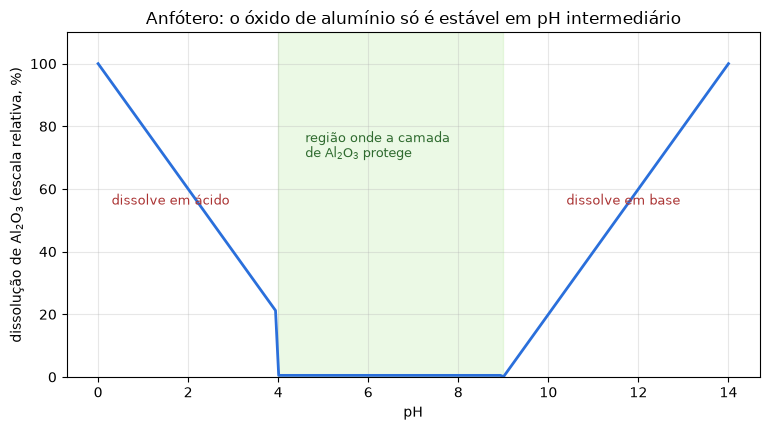

In [7]:
# @title Perda de alumínio em cada meio
import numpy as np
import matplotlib.pyplot as plt

ph = np.linspace(0, 14, 200)
# Curva esquemática: Al2O3 se dissolve em pH baixo ou alto, é estável perto de 6-7
dissolucao = np.piecewise(ph,
                          [ph < 4, (ph >= 4) & (ph <= 9), ph > 9],
                          [lambda p: 100 - 20 * p, 0.5,
                           lambda p: 20 * (p - 9)])

plt.figure(figsize=(7.8, 4.4))
plt.plot(ph, dissolucao, color="#2a6fdb", linewidth=2)
plt.axvspan(4, 9, color="#7ed957", alpha=0.15)
plt.text(4.6, 70, "região onde a camada\nde Al$_2$O$_3$ protege", fontsize=9, color="#2f6b2f")
plt.text(0.3, 55, "dissolve em ácido", fontsize=9, color="#a33")
plt.text(10.4, 55, "dissolve em base", fontsize=9, color="#a33")
plt.xlabel("pH")
plt.ylabel("dissolução de Al$_2$O$_3$ (escala relativa, %)")
plt.title("Anfótero: o óxido de alumínio só é estável em pH intermediário")
plt.ylim(0, 110)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.6 Óxidos e a saúde: o CO

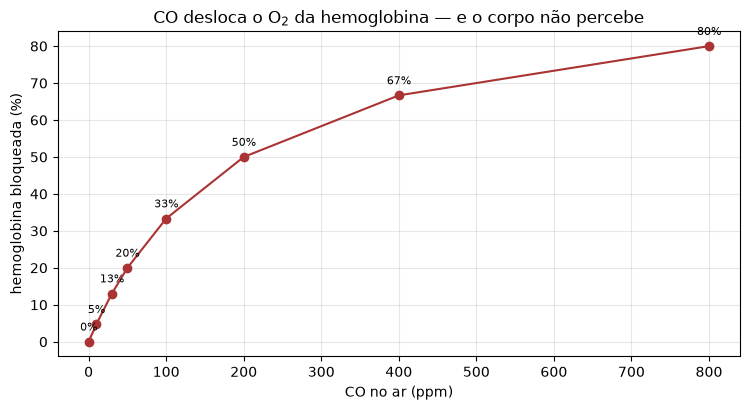

In [8]:
# @title Curva de saturação da hemoglobina
ppm = np.array([0, 10, 30, 50, 100, 200, 400, 800])
saturacao = 100 * ppm / (ppm + 200)     # curva esquemática (meia-saturação ~200 ppm)

plt.figure(figsize=(7.6, 4.2))
plt.plot(ppm, saturacao, marker="o", color="#a33")
for x, y in zip(ppm, saturacao):
    plt.annotate(f"{y:.0f}%", (x, y), xytext=(0, 8), textcoords="offset points",
                 ha="center", fontsize=8)
plt.xlabel("CO no ar (ppm)")
plt.ylabel("hemoglobina bloqueada (%)")
plt.title("CO desloca o O$_2$ da hemoglobina — e o corpo não percebe")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Como interpretar o resultado

- Anfoterismo não é "meio ácido meio básico": é a capacidade de reagir nos **dois** sentidos, dependendo do parceiro.
- A camada de $\mathrm{Al_2O_3}$ protege o alumínio entre pH 4 e 9; fora dessa faixa, o metal fica exposto e corrói.
- Óxidos neutros não formam sal: por isso o $\mathrm{CO}$ é tão perigoso — não há como "neutralizá-lo" no organismo.
- $\mathrm{Fe_3O_4}$ mostra que um óxido "misto" ($\mathrm{FeO\cdot Fe_2O_3}$) pode ter propriedades magnéticas diferentes das dos componentes — é o ímã de geladeira.

## 6. Exercício de fixação

Escreva as duas equações do $\mathrm{ZnO}$ (com $\mathrm{HCl}$ e com $\mathrm{NaOH}$) e diga qual delas mostra o óxido agindo como ácido.

In [9]:
# @title Exercício
respostas = {
    "com HCl": "ZnO + 2 HCl -> ZnCl2 + H2O  (óxido age como BASE)",
    "com NaOH": "ZnO + 2 NaOH -> Na2ZnO2 + H2O  (óxido age como ÁCIDO)",
}
for meio, equacao in respostas.items():
    print(f"{meio:9s} {equacao}")
print("\nComo base, o ZnO recebe próton; como ácido, ele doa o ânion ZnO2^2-.")

com HCl   ZnO + 2 HCl -> ZnCl2 + H2O  (óxido age como BASE)
com NaOH  ZnO + 2 NaOH -> Na2ZnO2 + H2O  (óxido age como ÁCIDO)

Como base, o ZnO recebe próton; como ácido, ele doa o ânion ZnO2^2-.


## 7. Resumo

- Anfótero = reage com ácido e com base (Al₂O₃, ZnO, PbO, SnO₂).
- Neutro = não reage com nenhum dos dois (CO, NO, N₂O).
- Óxidos mistos combinam dois NOx do mesmo metal (Fe₃O₄ = FeO·Fe₂O₃).
- Soda cáustica ataca o alumínio porque dissolve a camada anfótera de Al₂O₃.
- CO é tóxico por ligação forte com a hemoglobina.

## Referências

- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- FELTRE, R. *Química Geral*. Moderna.
- CETESB. *Qualidade do ar: monóxido de carbono*.